In [1]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().parent
data_dir = project_root / "data"

# Load all cleaned datasets using the Python CSV engine
customers = pd.read_csv(data_dir / "cleaned_customers.csv", engine="python")
orders = pd.read_csv(data_dir / "cleaned_orders.csv", engine="python")
order_items = pd.read_csv(data_dir / "cleaned_order_items.csv", engine="python")
products = pd.read_csv(data_dir / "cleaned_products.csv", engine="python")
regions = pd.read_csv(data_dir / "cleaned_regions.csv", engine="python")

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Regions": regions
}

print("All datasets loaded successfully!\n")

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")


All datasets loaded successfully!

Customers: 1,000 rows × 8 columns
Orders: 5,000 rows × 7 columns
Order Items: 10,000 rows × 7 columns
Products: 50 rows × 6 columns
Regions: 5 rows × 3 columns


In [2]:

for name, df in datasets.items():
    print(f"\n{'=' * 50}")
    print(name.upper())
    print("=" * 50)

    print("\nColumn names:")
    print(df.columns.tolist())

    print("\nData types:")
    display(df.dtypes.rename("Data Type").to_frame())

    print("\nSample records:")
    display(df.head(3))



CUSTOMERS

Column names:
['CustomerID', 'CustomerName', 'Email', 'JoinDate', 'RegionID', 'Age', 'Gender', 'AgeGroup']

Data types:


,Data Type
CustomerID,str
CustomerName,str
Email,str
JoinDate,str
RegionID,str
Age,float64
Gender,str
AgeGroup,str



Sample records:


,CustomerID,CustomerName,Email,JoinDate,RegionID,Age,Gender,AgeGroup
0,CUST-1001,Customer_0,customer_0@example.com,2024-04-12,REG-03,63.0,Female,50+
1,CUST-1002,Customer_1,customer_1@example.com,2025-03-11,REG-05,44.0,Female,36-50
2,CUST-1003,Customer_2,customer_2@example.com,2024-09-27,REG-01,46.0,Female,36-50



ORDERS

Column names:
['OrderID', 'CustomerID', 'OrderDate', 'ShipDate', 'OrderStatus', 'PaymentMethod', 'DeliveryDays']

Data types:


,Data Type
OrderID,str
CustomerID,str
OrderDate,str
ShipDate,str
OrderStatus,str
PaymentMethod,str
DeliveryDays,int64


... (10 outputs left out)


REGIONS

Column names:
['RegionID', 'RegionName', 'Country']

Data types:


,Data Type
RegionID,str
RegionName,str
Country,str



Sample records:


,RegionID,RegionName,Country
0,REG-01,North,India
1,REG-02,South,India
2,REG-03,East,India


In [3]:

quality_summary = []

for name, df in datasets.items():
    quality_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Cells": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

quality_df = pd.DataFrame(quality_summary)
display(quality_df)


,Dataset,Rows,Columns,Missing Cells,Duplicate Rows
0,Customers,1000,8,0,0
1,Orders,5000,7,0,0
2,Order Items,10000,7,0,0
3,Products,50,6,0,0
4,Regions,5,3,0,0


In [4]:

quality_summary = []

for name, df in datasets.items():
    quality_summary.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Cells": int(df.isna().sum().sum()),
        "Columns With Missing Values": int(df.isna().any().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    })

quality_df = pd.DataFrame(quality_summary)
display(quality_df)

print("\nMissing values by column:")
for name, df in datasets.items():
    missing = df.isna().sum()
    missing = missing[missing > 0]

    print(f"\n{name}:")
    if missing.empty:
        print("No missing values")
    else:
        display(missing.rename("Missing Count").to_frame())


,Dataset,Rows,Columns,Missing Cells,Columns With Missing Values,Duplicate Rows
0,Customers,1000,8,0,0,0
1,Orders,5000,7,0,0,0
2,Order Items,10000,7,0,0,0
3,Products,50,6,0,0,0
4,Regions,5,3,0,0,0



Missing values by column:

Customers:
No missing values

Orders:
No missing values

Order Items:
No missing values

Products:
No missing values

Regions:
No missing values


In [5]:

# Work on copies so the original loaded datasets remain unchanged
customers_eda = customers.copy()
orders_eda = orders.copy()
items_eda = order_items.copy()
products_eda = products.copy()
regions_eda = regions.copy()

# Convert date fields
customers_eda["JoinDate"] = pd.to_datetime(
    customers_eda["JoinDate"], errors="coerce"
)
orders_eda["OrderDate"] = pd.to_datetime(
    orders_eda["OrderDate"], errors="coerce"
)
orders_eda["ShipDate"] = pd.to_datetime(
    orders_eda["ShipDate"], errors="coerce"
)

# Join transaction-level data with dimensions
eda_data = (
    items_eda
    .merge(orders_eda, on="OrderID", how="left", validate="many_to_one")
    .merge(products_eda, on="ProductID", how="left", validate="many_to_one")
    .merge(
        customers_eda[["CustomerID", "Age", "Gender", "AgeGroup", "RegionID"]],
        on="CustomerID",
        how="left",
        validate="many_to_one"
    )
    .merge(
        regions_eda,
        on="RegionID",
        how="left",
        validate="many_to_one"
    )
)

# Create date-analysis columns
eda_data["OrderMonth"] = eda_data["OrderDate"].dt.to_period("M").astype("string")
eda_data["OrderYear"] = eda_data["OrderDate"].dt.year

print("Analysis dataset created successfully")
print("Shape:", eda_data.shape)
print("\nColumns:")
print(eda_data.columns.tolist())

display(eda_data.head())


Analysis dataset created successfully
Shape: (10000, 26)

Columns:
['OrderItemID', 'OrderID', 'ProductID', 'Quantity', 'Discount', 'LineTotal', 'LineProfit', 'CustomerID', 'OrderDate', 'ShipDate', 'OrderStatus', 'PaymentMethod', 'DeliveryDays', 'ProductName', 'Category', 'SubCategory', 'UnitPrice', 'CostPrice', 'Age', 'Gender', 'AgeGroup', 'RegionID', 'RegionName', 'Country', 'OrderMonth', 'OrderYear']


,OrderItemID,OrderID,ProductID,Quantity,Discount,LineTotal,LineProfit,CustomerID,OrderDate,ShipDate,...,UnitPrice,CostPrice,Age,Gender,AgeGroup,RegionID,RegionName,Country,OrderMonth,OrderYear
0,ITEM-100000,ORD-2026-11665,PROD-520,4,0.00,86352.04,15422.04,CUST-1206,2025-06-27,2025-07-03,...,21588.01,17732.50,69.0,Female,50+,REG-04,West,India,2025-06,2025
1,ITEM-100001,ORD-2026-13199,PROD-511,3,0.05,1225.36,255.84,CUST-1154,2025-04-21,2025-04-25,...,429.95,340.18,55.0,Male,50+,REG-02,South,India,2025-04,2025
2,ITEM-100002,ORD-2026-14496,PROD-530,2,0.10,28624.54,10538.23,CUST-1049,2026-01-30,2026-01-31,...,15902.52,10047.95,32.0,Female,26-35,REG-04,West,India,2026-01,2026
3,ITEM-100003,ORD-2026-11595,PROD-527,4,0.15,62346.17,17689.86,CUST-1869,2026-05-31,2026-06-02,...,18337.11,13134.21,68.0,Female,50+,REG-04,West,India,2026-05,2026
4,ITEM-100004,ORD-2026-11989,PROD-539,3,0.05,53465.49,12727.81,CUST-1090,2025-12-05,2025-12-10,...,18759.82,14293.92,49.0,Male,36-50,REG-03,East,India,2025-12,2025


In [6]:

total_revenue = eda_data["LineTotal"].sum()
total_profit = eda_data["LineProfit"].sum()
total_orders = eda_data["OrderID"].nunique()
units_sold = eda_data["Quantity"].sum()
total_customers = eda_data["CustomerID"].nunique()

average_order_value = (
    total_revenue / total_orders if total_orders else 0
)
profit_margin = (
    total_profit / total_revenue * 100 if total_revenue else 0
)

kpi_summary = pd.DataFrame({
    "KPI": [
        "Total Revenue",
        "Total Profit",
        "Total Orders",
        "Units Sold",
        "Unique Customers",
        "Average Order Value",
        "Profit Margin (%)"
    ],
    "Value": [
        round(total_revenue, 2),
        round(total_profit, 2),
        total_orders,
        units_sold,
        total_customers,
        round(average_order_value, 2),
        round(profit_margin, 2)
    ]
})

display(kpi_summary)


,KPI,Value
0,Total Revenue,3.028572e+08
1,Total Profit,7.843018e+07
2,Total Orders,4.307000e+03
3,Units Sold,2.497300e+04
4,Unique Customers,9.850000e+02
5,Average Order Value,7.031744e+04
6,Profit Margin (%),2.590000e+01


,OrderMonth,Revenue,Profit,Orders
0,2025-01,17760880.10,4590884.26,244
1,2025-02,13011778.04,3255928.12,183
2,2025-03,16822020.47,4360467.00,237
3,2025-04,15051556.05,3919886.42,216
4,2025-05,14301586.08,3731448.75,208
5,2025-06,15330637.57,3986477.92,223
6,2025-07,13403736.40,3484838.38,195
7,2025-08,17388642.64,4508753.39,231
8,2025-09,14969854.75,3850789.89,223
9,2025-10,16745372.70,4257503.20,227


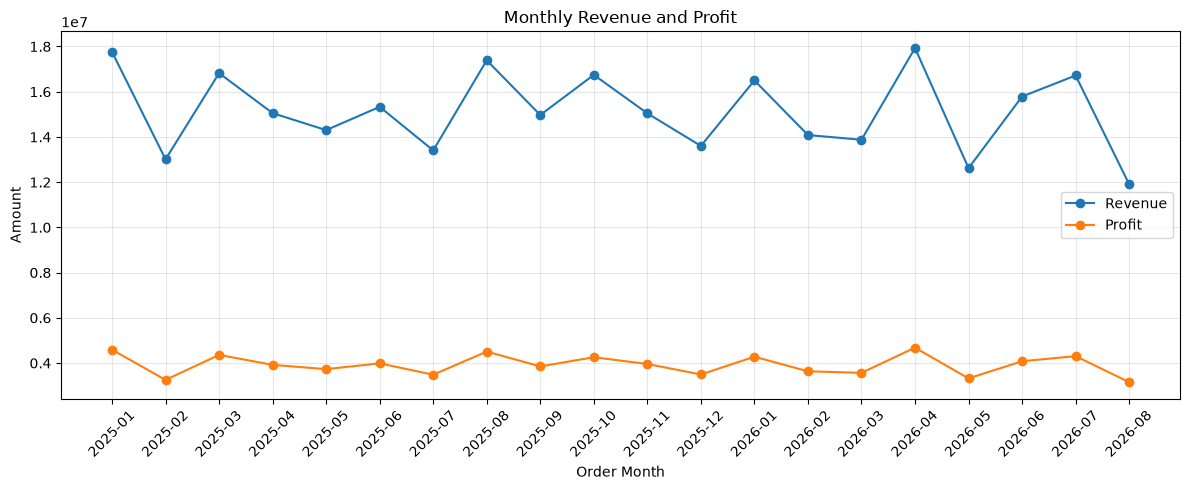

In [7]:

monthly_sales = (
    eda_data.dropna(subset=["OrderDate"])
    .groupby("OrderMonth", as_index=False)
    .agg(
        Revenue=("LineTotal", "sum"),
        Profit=("LineProfit", "sum"),
        Orders=("OrderID", "nunique")
    )
)

monthly_sales["OrderMonth"] = monthly_sales["OrderMonth"].astype(str)

display(monthly_sales)

plt.figure(figsize=(12, 5))
plt.plot(
    monthly_sales["OrderMonth"],
    monthly_sales["Revenue"],
    marker="o",
    label="Revenue"
)
plt.plot(
    monthly_sales["OrderMonth"],
    monthly_sales["Profit"],
    marker="o",
    label="Profit"
)

plt.title("Monthly Revenue and Profit")
plt.xlabel("Order Month")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [8]:
# Category-wise sales and profit analysis

category_performance = (
    eda_data
    .groupby("Category", as_index=False)
    .agg(
        Revenue=("LineTotal", "sum"),
        Profit=("LineProfit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Orders=("OrderID", "nunique")
    )
)

category_performance["ProfitMargin (%)"] = (
    category_performance["Profit"]
    / category_performance["Revenue"]
    * 100
)

category_performance = category_performance.sort_values(
    by="Revenue",
    ascending=False
)

display(category_performance.round(2))

,Category,Revenue,Profit,Units_Sold,Orders,ProfitMargin (%)
0,Apparel,96630478.79,24926246.09,7213,2215,25.80
1,Electronics,86482439.65,22748348.99,6779,2079,26.30
2,Home & Kitchen,60166628.24,14466010.11,5572,1763,24.04
3,Sports,59577655.65,16289575.39,5409,1770,27.34


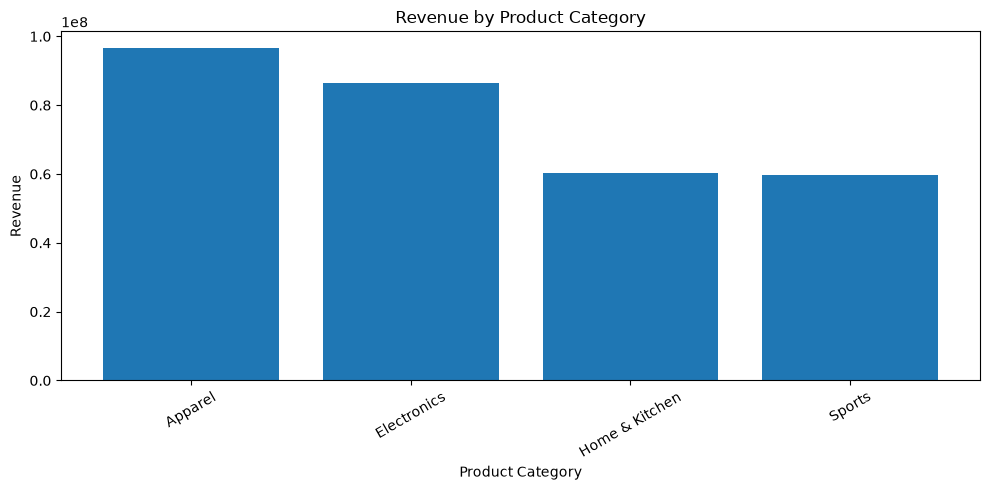

In [9]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_performance["Category"],
    category_performance["Revenue"]
)

plt.title("Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [10]:
# Top 10 products by revenue

top_products = (
    eda_data
    .groupby(["ProductID", "ProductName"], as_index=False)
    .agg(
        Revenue=("LineTotal", "sum"),
        Profit=("LineProfit", "sum"),
        Units_Sold=("Quantity", "sum"),
        Orders=("OrderID", "nunique")
    )
    .sort_values("Revenue", ascending=False)
    .head(10)
)

display(top_products.round(2))

,ProductID,ProductName,Revenue,Profit,Units_Sold,Orders
40,PROD-541,Product_40,12374386.49,4080818.29,528,210
43,PROD-544,Product_43,11573386.45,3242689.39,556,210
19,PROD-520,Product_19,11345578.83,2026263.31,555,216
27,PROD-528,Product_27,11055369.42,2006077.24,526,215
5,PROD-506,Product_5,11009045.46,1835410.46,586,224
6,PROD-507,Product_6,10615858.14,3081001.23,506,203
0,PROD-501,Product_0,10611177.44,2718027.60,496,199
38,PROD-539,Product_38,10180016.47,2423420.50,570,224
21,PROD-522,Product_21,9963384.43,2205293.69,528,199
2,PROD-503,Product_2,9393680.24,1537946.43,482,189


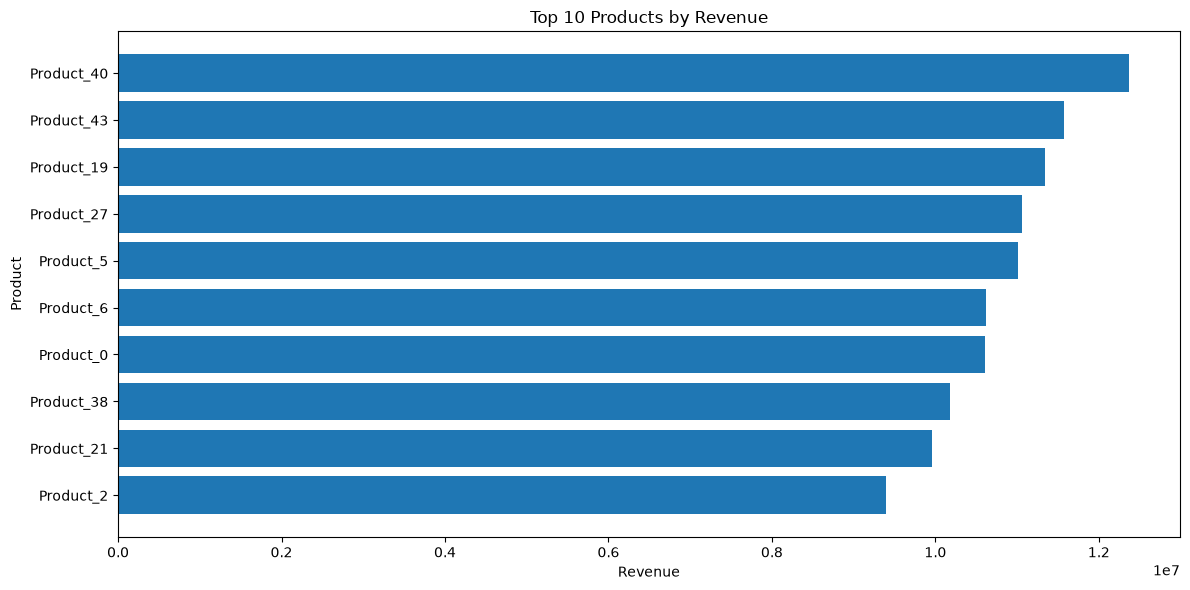

In [11]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_products["ProductName"][::-1],
    top_products["Revenue"][::-1]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [12]:
# Top 10 customers by total spending

top_customers = (
    eda_data
    .groupby("CustomerID", as_index=False)
    .agg(
        Total_Spending=("LineTotal", "sum"),
        Total_Profit=("LineProfit", "sum"),
        Total_Orders=("OrderID", "nunique"),
        Total_Units=("Quantity", "sum")
    )
    .sort_values("Total_Spending", ascending=False)
    .head(10)
)

display(top_customers.round(2))

,CustomerID,Total_Spending,Total_Profit,Total_Orders,Total_Units
687,CUST-1699,1269318.05,317624.97,10,88
745,CUST-1758,1076240.89,277216.02,10,73
646,CUST-1658,1005124.19,274770.75,11,82
233,CUST-1237,982658.68,280800.23,11,76
969,CUST-1984,936856.64,256310.69,8,72
958,CUST-1973,924826.78,236077.39,9,63
858,CUST-1871,891664.63,230152.51,9,70
708,CUST-1720,881318.34,202505.93,12,77
207,CUST-1211,870584.68,228792.61,7,66
203,CUST-1207,855858.74,222686.15,9,59


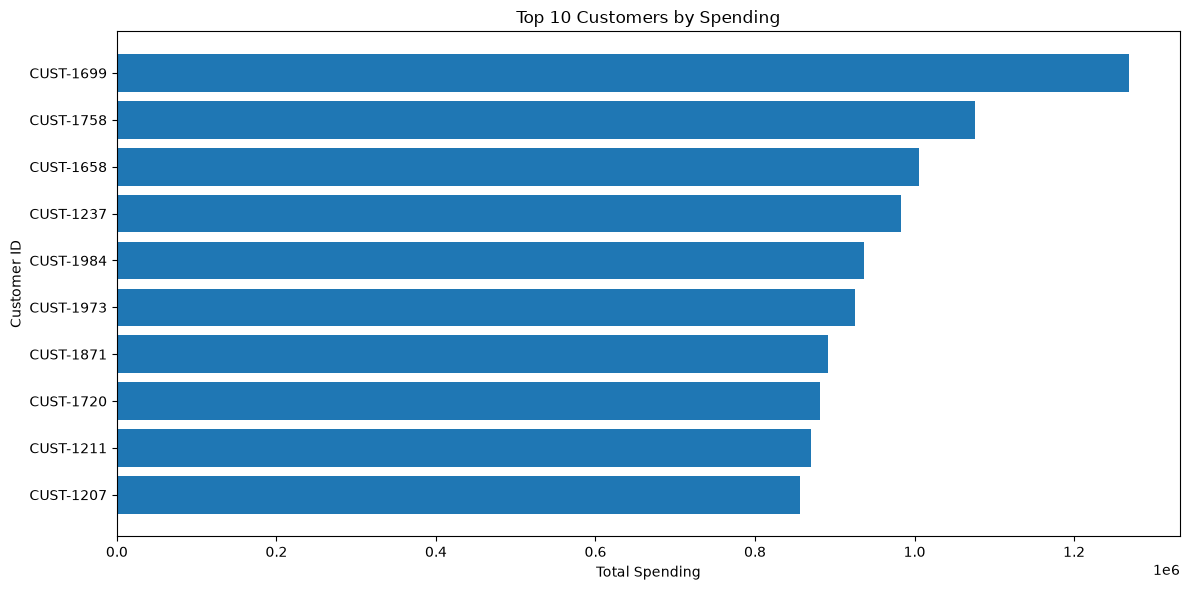

In [13]:
plt.figure(figsize=(12, 6))

plt.barh(
    top_customers["CustomerID"][::-1],
    top_customers["Total_Spending"][::-1]
)

plt.title("Top 10 Customers by Spending")
plt.xlabel("Total Spending")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

In [14]:
# Regional sales and profit analysis

regional_performance = (
    eda_data
    .groupby(["RegionName", "Country"], as_index=False)
    .agg(
        Revenue=("LineTotal", "sum"),
        Profit=("LineProfit", "sum"),
        Orders=("OrderID", "nunique"),
        Units_Sold=("Quantity", "sum"),
        Customers=("CustomerID", "nunique")
    )
)

regional_performance["ProfitMargin (%)"] = (
    regional_performance["Profit"]
    / regional_performance["Revenue"]
    * 100
)

regional_performance = regional_performance.sort_values(
    "Revenue", ascending=False
)

display(regional_performance.round(2))

,RegionName,Country,Revenue,Profit,Orders,Units_Sold,Customers,ProfitMargin (%)
0,Central,India,63065257.73,16477139.49,900,5285,205,26.13
1,East,India,61898336.28,16066379.95,868,5112,191,25.96
3,South,India,60293275.66,15484912.39,857,4941,200,25.68
2,North,India,60261259.46,15612285.71,846,4849,202,25.91
4,West,India,57339073.20,14789463.04,836,4786,187,25.79


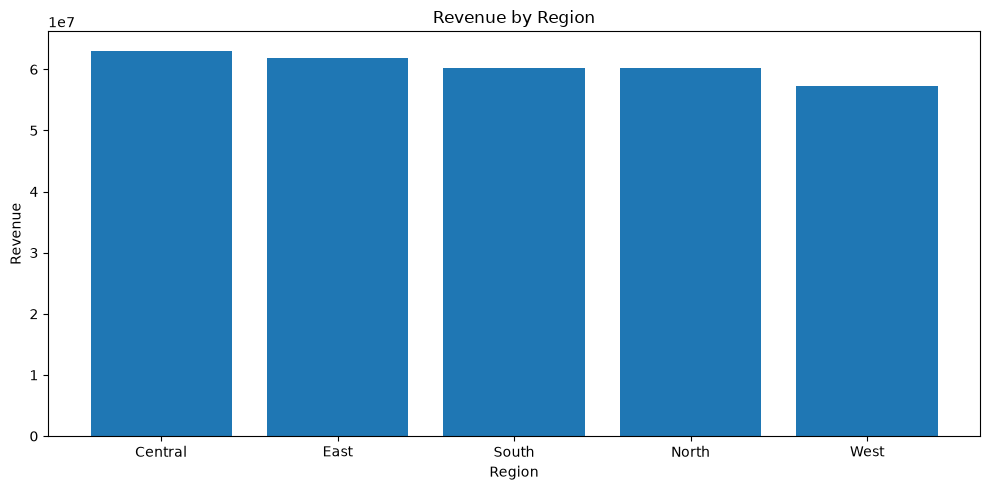

In [15]:
plt.figure(figsize=(10, 5))

plt.bar(
    regional_performance["RegionName"],
    regional_performance["Revenue"]
)

plt.title("Revenue by Region")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.tight_layout()
plt.show()

In [16]:
regional_performance[
    ["RegionName", "Revenue", "Profit", "ProfitMargin (%)"]
].round(2)

,RegionName,Revenue,Profit,ProfitMargin (%)
0,Central,63065257.73,16477139.49,26.13
1,East,61898336.28,16066379.95,25.96
3,South,60293275.66,15484912.39,25.68
2,North,60261259.46,15612285.71,25.91
4,West,57339073.20,14789463.04,25.79


In [17]:
# Order status analysis

order_status_analysis = (
    orders_eda
    .groupby("OrderStatus", as_index=False)
    .agg(
        Total_Orders=("OrderID", "nunique")
    )
    .sort_values("Total_Orders", ascending=False)
)

display(order_status_analysis)

,OrderStatus,Total_Orders
1,Delivered,4005
3,Shipped,509
0,Cancelled,247
2,Processing,239


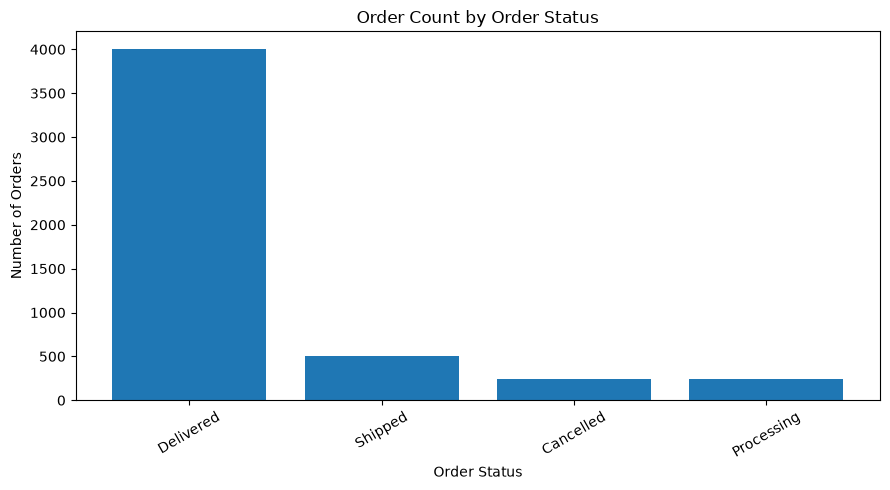

In [18]:
plt.figure(figsize=(9, 5))

plt.bar(
    order_status_analysis["OrderStatus"],
    order_status_analysis["Total_Orders"]
)

plt.title("Order Count by Order Status")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [19]:
# 1. Order status analysis
print("ORDER STATUS ANALYSIS")
order_status = (
    orders_eda.groupby("OrderStatus", as_index=False)
    .agg(Orders=("OrderID", "nunique"))
    .sort_values("Orders", ascending=False)
)
display(order_status)

# 2. Payment method analysis
print("PAYMENT METHOD ANALYSIS")
payment_analysis = (
    orders_eda.groupby("PaymentMethod", as_index=False)
    .agg(Orders=("OrderID", "nunique"))
    .sort_values("Orders", ascending=False)
)
display(payment_analysis)

# 3. Delivery time analysis
print("DELIVERY TIME ANALYSIS")
delivery_analysis = (
    orders_eda.groupby("OrderStatus", as_index=False)
    .agg(
        Average_Delivery_Days=("DeliveryDays", "mean"),
        Median_Delivery_Days=("DeliveryDays", "median"),
        Orders=("OrderID", "nunique")
    )
)
display(delivery_analysis.round(2))

# 4. Discount and profitability analysis
print("DISCOUNT PROFITABILITY ANALYSIS")
discount_analysis = (
    eda_data.groupby("Discount", as_index=False)
    .agg(
        Revenue=("LineTotal", "sum"),
        Profit=("LineProfit", "sum"),
        Order_Items=("OrderItemID", "count")
    )
    .sort_values("Discount")
)
discount_analysis["ProfitMargin (%)"] = (
    discount_analysis["Profit"]
    / discount_analysis["Revenue"] * 100
)
display(discount_analysis.round(2))

ORDER STATUS ANALYSIS


,OrderStatus,Orders
1,Delivered,4005
3,Shipped,509
0,Cancelled,247
2,Processing,239


PAYMENT METHOD ANALYSIS


,PaymentMethod,Orders
2,Net Banking,1291
0,Cash on Delivery,1277
3,UPI,1227
1,Credit Card,1205


DELIVERY TIME ANALYSIS


,OrderStatus,Average_Delivery_Days,Median_Delivery_Days,Orders
0,Cancelled,3.58,4.0,247
1,Delivered,3.49,3.0,4005
2,Processing,3.60,4.0,239
3,Shipped,3.50,3.0,509


DISCOUNT PROFITABILITY ANALYSIS


,Discount,Revenue,Profit,Order_Items,ProfitMargin (%)
0,0.00,1.594869e+08,41537727.33,4989,26.04
1,0.05,6.086925e+07,15741791.42,1981,25.86
2,0.10,4.050393e+07,10372443.86,1490,25.61
3,0.15,2.904357e+07,7507307.45,1034,25.85
4,0.20,1.295354e+07,3270910.52,506,25.25


In [20]:
# Final Python EDA validation

print("FINAL EDA VALIDATION")
print("-" * 40)

print("Analysis dataset rows:", len(eda_data))
print("Analysis dataset columns:", len(eda_data.columns))
print("Unique orders:", eda_data["OrderID"].nunique())
print("Unique customers:", eda_data["CustomerID"].nunique())
print("Missing values:", eda_data.isna().sum().sum())
print("Duplicate rows:", eda_data.duplicated().sum())

print("\nRevenue total:", round(eda_data["LineTotal"].sum(), 2))
print("Profit total:", round(eda_data["LineProfit"].sum(), 2))

print("\nDate range:")
print("Start:", eda_data["OrderDate"].min())
print("End:", eda_data["OrderDate"].max())

FINAL EDA VALIDATION
----------------------------------------
Analysis dataset rows: 10000
Analysis dataset columns: 26
Unique orders: 4307
Unique customers: 985
Missing values: 0
Duplicate rows: 0

Revenue total: 302857202.33
Profit total: 78430180.58

Date range:
Start: 2025-01-01 00:00:00
End: 2026-08-23 00:00:00
